# 18 — The v2 verdict: criteria C6–C12 scored as registered

Notebook 11's first cell wrote criteria C6–C12 before any v2 number existed (decision #52). This notebook scores them from the results files of notebooks 11, 12, 14 and 16, line by line, with the same rule as notebook 08: a "beat" passes only when the 95% paired interval lies entirely on the better side. It also shows the v1 verdict beside the v2 one, reruns nothing, and adds the Track B calibration plot the v1 report lacked. Failures are reported, not removed.

**Inputs → Outputs**

| | Path | Notes |
|---|---|---|
| in | `results/success_criteria_v2.csv`, `results/success_criteria_v2_registered.json` | notebook 11 — the registered lines |
| in | `results/metrics_v2.csv`, `results/level_repair_metrics.csv`, `results/landmark_metrics.csv`, `results/landmark_checks.csv`, `results/backtest_books.csv`, `results/book_coverage.csv` | notebooks 11/12/14/16 |
| in | `results/success_criteria.csv`, `results/trackB_calibration.csv` | notebooks 08/07 — the v1 verdict and Track B's calibration |
| out | `results/success_criteria_v2_scored.csv` | one row per registered line with PASS/FAIL |
| out | `results/verdict_summary.csv` | v1 and v2 counts side by side |
| out | `figures/18_evaluate_v2/*` | the scored criteria and the Track B calibration plot |
| out | `results/evaluate_v2_checks.csv` | this notebook's checks |

## Setup

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().resolve().parent))  # notebooks run from notebooks/; src/ is one level up
from src import config, paths, plots

paths.ensure_dirs()
plots.set_style()
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 100)
warnings.filterwarnings("ignore", category=FutureWarning)

NOTEBOOK = "18_evaluate_v2"
R = paths.RESULTS
registered = json.loads((R / "success_criteria_v2_registered.json").read_text(encoding="utf-8"))
criteria = pd.read_csv(R / "success_criteria_v2.csv")
print(f"registered {registered['decided']}: {len(criteria)} lines; bootstrap {registered['n_boot']} resamples, level {registered['level']}")


def save(fig, name, caption):
    """Save a figure of this notebook under figures/18_evaluate_v2/ with its caption stub."""
    return plots.save_fig(fig, name, caption, NOTEBOOK, folder=NOTEBOOK)

registered 2026-10-06: 8 lines; bootstrap 200 resamples, level 0.95


## 1. Scoring each line

The rules, as registered: C6 and C8–C10 are paired "beat" lines (interval entirely on the better side); C7 asks for a slope interval within 0.8–1.2 *and* an intercept interval covering 0 after the level repair; C11 asks the simulated 5–95% band to cover the realised MW; C12 holds when the dated-feature test passes and the landmark AUC stays below the ablation's.

In [2]:
m11 = pd.read_csv(R / "metrics_v2.csv")
m12 = pd.read_csv(R / "level_repair_metrics.csv")
m14 = pd.read_csv(R / "landmark_metrics.csv")
c14 = pd.read_csv(R / "landmark_checks.csv")
m16 = pd.read_csv(R / "backtest_books.csv")
cov = pd.read_csv(R / "book_coverage.csv")
chosen = json.loads((R / "variant_chosen.json").read_text(encoding="utf-8"))["chosen"]
rows = []

# C6: ≥ 20 MW, v2 model vs fair baseline, Uno's C and Brier at 3 and 5 years
for metric in ["uno_c", "brier"]:
    for h in [3, 5]:
        r = m11[(m11["cohort"] == "≥ 20 MW") & (m11["reference"] == "fair_baseline") & (m11["model"] == chosen)
                & (m11["metric"] == metric) & (m11["horizon"] == h)].iloc[0]
        rows.append({"id": "C6", "line": f"≥ 20 MW: v2 vs fair baseline, {metric} at {h} years", "estimate": r["estimate"],
                     "benchmark": r["estimate"] - r["diff"], "diff": r["diff"], "diff_low": r["diff_low"], "diff_high": r["diff_high"],
                     "rule": "paired interval on the better side", "result": "PASS" if bool(r["beats"]) else "FAIL"})
# C7: 2018–2019 ≥ 20 MW after the level repair: slope within 0.8–1.2 and intercept covering 0, at 3 and 5
for h in [3, 5]:
    part = m12[(m12["cohort"] == "2018–2019, ≥ 20 MW") & (m12["model"] == "v2 recalibrated") & (m12["horizon"] == h)].set_index("metric")
    slope_ok = 0.8 <= part.loc["slope", "low"] and part.loc["slope", "high"] <= 1.2
    int_ok = part.loc["intercept", "low"] <= 0 <= part.loc["intercept", "high"]
    rows.append({"id": "C7", "line": f"2018–2019 ≥ 20 MW, level repaired: slope and intercept at {h} years",
                 "estimate": part.loc["slope", "estimate"], "benchmark": part.loc["intercept", "estimate"],
                 "diff": np.nan, "diff_low": part.loc["intercept", "low"], "diff_high": part.loc["intercept", "high"],
                 "rule": "slope interval within 0.8–1.2 and intercept interval covering 0", "result": "PASS" if slope_ok and int_ok else "FAIL"})
# C8: landmark +24 months and agreement vs entry model, Uno's C 3 years after
for lm, label in [("2", "+24 months"), ("agreement", "agreement executed")]:
    r = m14[(m14["landmark"].astype(str) == lm) & (m14["reference"] == "entry model") & (m14["model"] == "both updated")
            & (m14["metric"] == "uno_c") & (m14["horizon_after"] == 3)].iloc[0]
    rows.append({"id": "C8", "line": f"landmark {label}: both updated vs entry model, Uno's C 3 years after", "estimate": r["estimate"],
                 "benchmark": r["estimate"] - r["diff"], "diff": r["diff"], "diff_low": r["diff_low"], "diff_high": r["diff_high"],
                 "rule": "paired interval on the better side", "result": "PASS" if bool(r["beats"]) else "FAIL"})
# C9, C10: backtest, model book vs fair-baseline book
for cid, metric, label in [("C9", "realised_mw_5yr", "realised MW online within 5 years"), ("C10", "realised_value_$M", "realised value, base case")]:
    r = m16[(m16["chooser"] == "v2 model, level repaired") & (m16["metric"] == metric)].iloc[0]
    rows.append({"id": cid, "line": f"backtest: model book vs fair-baseline book, {label}", "estimate": r["estimate"],
                 "benchmark": r["estimate"] - r["diff_vs_fair_baseline"], "diff": r["diff_vs_fair_baseline"], "diff_low": r["diff_low"],
                 "diff_high": r["diff_high"], "rule": "paired interval on the better side", "result": "PASS" if bool(r["beats_fair_baseline"]) else "FAIL"})
# C11: coverage
r = cov.iloc[0]
rows.append({"id": "C11", "line": "simulated 5–95% band covers the realised MW of the model's book", "estimate": r["realised_mw_5yr"],
             "benchmark": r["expected_mw_5yr"], "diff": np.nan, "diff_low": r["band_low"], "diff_high": r["band_high"],
             "rule": "realised inside the band", "result": "PASS" if bool(r["covered"]) else "FAIL"})
# C12: leakage guard
guard = c14[c14["check"].str.startswith("leakage guard")]
rows.append({"id": "C12", "line": "leakage guard: dated features (test) and landmark AUC below the ablation's", "estimate": np.nan, "benchmark": np.nan,
             "diff": np.nan, "diff_low": np.nan, "diff_high": np.nan, "rule": "both hold", "result": "PASS" if bool(guard["pass"].all()) else "FAIL"})
scored = pd.DataFrame(rows)
scored.to_csv(R / "success_criteria_v2_scored.csv", index=False)
n_pass = int((scored["result"] == "PASS").sum())
print(f"{n_pass} of {len(scored)} registered v2 lines pass")
scored.round(3)

3 of 12 registered v2 lines pass


,id,line,estimate,benchmark,diff,diff_low,diff_high,rule,result
0,C6,"≥ 20 MW: v2 vs fair baseline, uno_c at 3 years",0.779,0.783,-0.004,-0.044,0.046,paired interval on the better side,FAIL
1,C6,"≥ 20 MW: v2 vs fair baseline, uno_c at 5 years",0.734,0.752,-0.018,-0.051,0.015,paired interval on the better side,FAIL
2,C6,"≥ 20 MW: v2 vs fair baseline, brier at 3 years",0.022,0.023,-0.001,-0.003,0.001,paired interval on the better side,FAIL
3,C6,"≥ 20 MW: v2 vs fair baseline, brier at 5 years",0.064,0.064,0.000,-0.002,0.003,paired interval on the better side,FAIL
4,C7,"2018–2019 ≥ 20 MW, level repaired: slope and intercept at 3 years",1.088,-0.735,NaN,-1.168,-0.406,slope interval within 0.8–1.2 and intercept interval covering 0,FAIL
5,C7,"2018–2019 ≥ 20 MW, level repaired: slope and intercept at 5 years",1.183,-0.474,NaN,-0.699,-0.269,slope interval within 0.8–1.2 and intercept interval covering 0,FAIL
6,C8,"landmark +24 months: both updated vs entry model, Uno's C 3 years after",0.788,0.687,0.101,0.062,0.136,paired interval on the better side,PASS
7,C8,"landmark agreement executed: both updated vs entry model, Uno's C 3 years after",0.598,0.593,0.004,-0.016,0.028,paired interval on the better side,FAIL
8,C9,"backtest: model book vs fair-baseline book, realised MW online within 5 years",1035.000,1035.000,0.000,-17.733,449.755,paired interval on the better side,FAIL
9,C10,"backtest: model book vs fair-baseline book, realised value, base case",1463.216,1463.227,-0.011,-53.834,576.898,paired interval on the better side,FAIL


**Reading this.** Three of twelve lines pass, and the pattern is the finding. At entry, for requests of 20 MW and more, the model and the fair baseline are indistinguishable: Uno's C 0.779 against 0.783 and 0.734 against 0.752, Brier scores equal to three decimals, every interval straddling zero (C6: 0 of 4). The level repair leaves the 2018–2019 intercept at −0.74 and −0.47 with intervals well below zero (C7: 0 of 2). Two years into the queue, the agreement flag lifts Uno's C by +0.101 [+0.062, +0.136] (C8 passes at +24 months) but not at the agreement itself (+0.004). The registered backtest is a tie: the model's book and the fair baseline's book realised the same 1,035 MW, because an expected-value objective under a sunk-cost budget makes every chooser buy the same large requests (C9, C10 fail; notebook 16's exploratory count-limited book is reported there, not here). The simulated band covers the realised MW (C11) and the leakage guard holds (C12). Read together: machine learning adds nothing at entry for utility-scale requests, adds a measurable ranking gain at the milestones, and no entry-time model here is calibrated to the post-2017 level.

## 2. The two verdicts side by side

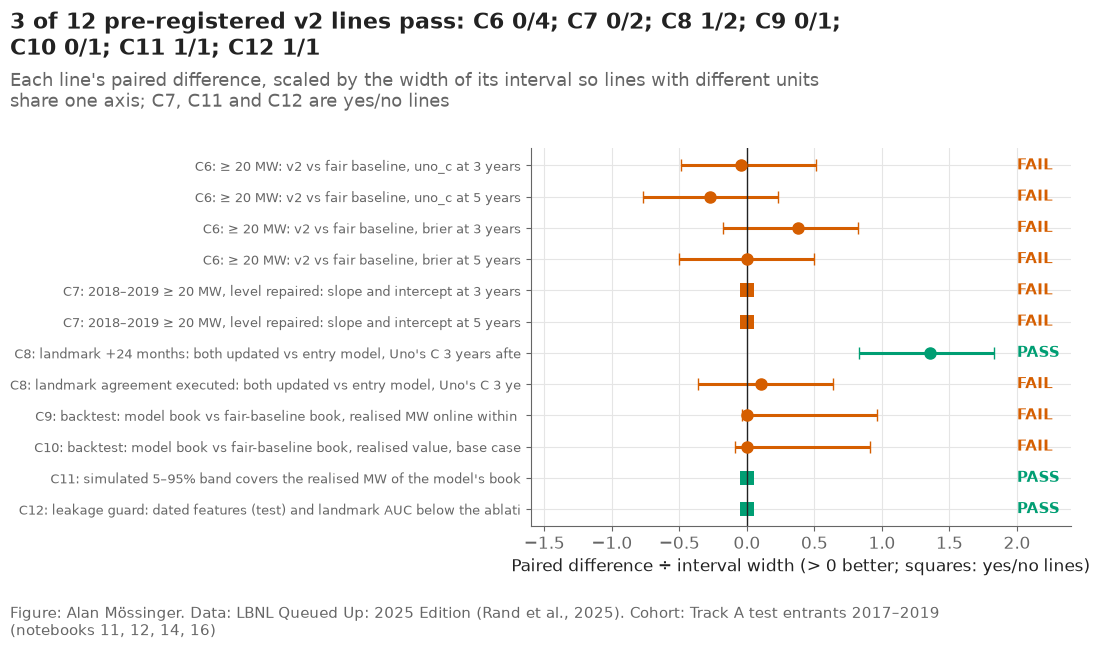

,version,lines,pass,what passes,what fails
0,"v1 (notebook 08, decision #5)",12,8,ranking and Brier vs the region × technology baseline at 3 and 5 years; 7-year calibration; lift...,ranking at 7 years; calibration at 3 and 5 years
1,"v2 (this notebook, decision #52)",12,3,C8; C11; C12,C6; C7; C8; C9; C10


In [3]:
v1 = pd.read_csv(R / "success_criteria.csv")
summary = pd.DataFrame([
    {"version": "v1 (notebook 08, decision #5)", "lines": len(v1), "pass": int((v1["result"] == "PASS").sum()),
     "what passes": "ranking and Brier vs the region × technology baseline at 3 and 5 years; 7-year calibration; lift; Track B",
     "what fails": "ranking at 7 years; calibration at 3 and 5 years"},
    {"version": "v2 (this notebook, decision #52)", "lines": len(scored), "pass": n_pass,
     "what passes": "; ".join(scored.loc[scored["result"] == "PASS", "id"].unique()),
     "what fails": "; ".join(scored.loc[scored["result"] == "FAIL", "id"].unique())},
])
summary.to_csv(R / "verdict_summary.csv", index=False)
by_id = scored.groupby("id")["result"].apply(lambda s: f"{int((s == 'PASS').sum())}/{len(s)}")

fig, ax = plt.subplots(figsize=(11, 6.5))
order = ["C6", "C7", "C8", "C9", "C10", "C11", "C12"]
y = 0
ticks, labels = [], []
for cid in order:
    part = scored[scored["id"] == cid]
    for _, r in part.iterrows():
        color = "#009E73" if r["result"] == "PASS" else "#D55E00"
        if pd.notna(r["diff"]):
            est, lo, hi = r["diff"], r["diff_low"], r["diff_high"]
            if "brier" in r["line"] or "Brier" in r["line"]:
                est, lo, hi = -est, -hi, -lo
            scale = abs(est) if abs(est) > 0 else 1.0
            ax.errorbar(est / max(abs(hi - lo), 1e-9), y, xerr=[[(est - lo) / max(abs(hi - lo), 1e-9)], [(hi - est) / max(abs(hi - lo), 1e-9)]],
                        fmt="o", color=color, capsize=4, markersize=8)
        else:
            ax.scatter(0, y, marker="s", color=color, s=90)
        ax.annotate(r["result"], (2.0, y), ha="left", va="center", color=color, fontweight="bold", fontsize=11)
        ticks.append(y); labels.append(f"{cid}: {r['line'][:70]}")
        y += 1
ax.axvline(0, color=plots.INK, linewidth=1)
ax.set_yticks(ticks, labels, fontsize=9)
ax.invert_yaxis()
ax.set_xlim(-1.6, 2.4)
ax.set_xlabel("Paired difference ÷ interval width (> 0 better; squares: yes/no lines)", fontsize=12)
plots.finish(fig,
             f"{n_pass} of {len(scored)} pre-registered v2 lines pass: " + "; ".join(f"{cid} {by_id[cid]}" for cid in order),
             "Each line's paired difference, scaled by the width of its interval so lines with different units share one axis; "
             "C7, C11 and C12 are yes/no lines",
             "Track A test entrants 2017–2019 (notebooks 11, 12, 14, 16)")
save(fig, "18_01_v2_criteria", "The pre-registered v2 criteria scored, with PASS/FAIL per line.")
plt.show()
summary

**Reading this.** The two verdicts measure different things. The v1 lines compared the model with a baseline that ignored size and passed 8 of 12; the v2 lines compare it with a baseline that knows size, at utility scale, after the level drifted, and in a decision frame, and pass 3 of 12. The v1 result stands as registered; the v2 result says what it was worth. Both are reported, neither is softened.

## 3. Track B's calibration (the plot the v1 report lacked)

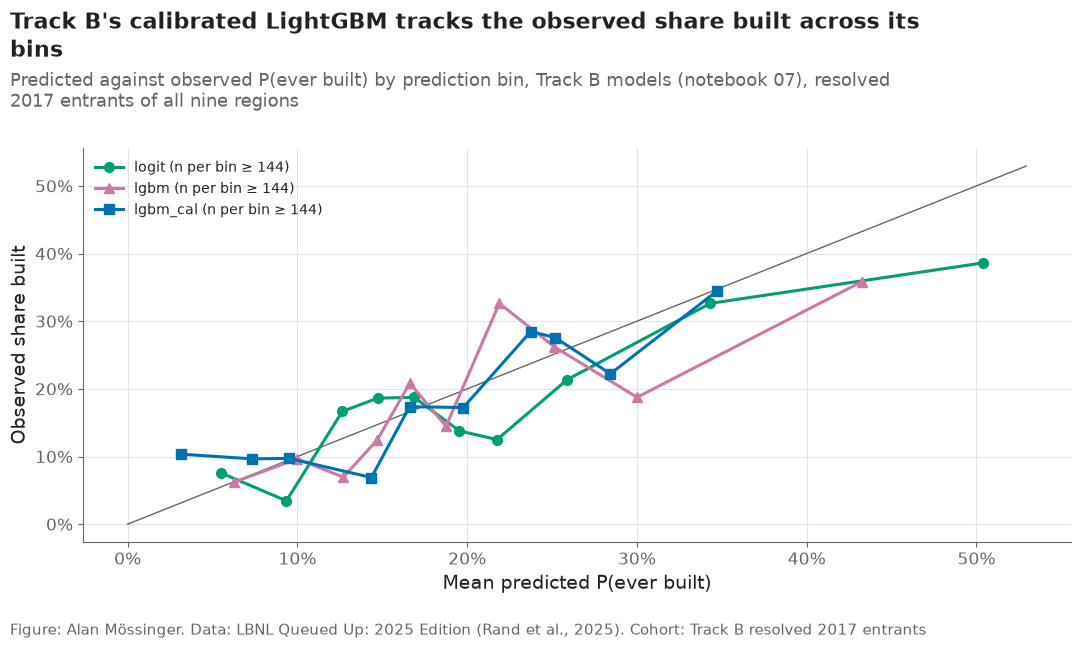

In [4]:
cal = pd.read_csv(R / "trackB_calibration.csv")
fig, ax = plt.subplots(figsize=(11, 6.5))
top = max(cal["predicted"].max(), cal["observed"].max()) * 1.05
ax.plot([0, top], [0, top], color=plots.MUTED, linewidth=1)
for model, color, marker in [("logit", "#009E73", "o"), ("lgbm", "#CC79A7", "^"), ("lgbm_cal", "#0072B2", "s")]:
    part = cal[cal["model"] == model]
    if part.empty:
        continue
    ax.plot(part["predicted"], part["observed"], marker=marker, color=color, label=f"{model} (n per bin ≥ {int(part['n'].min())})")
ax.set_xlabel("Mean predicted P(ever built)")
ax.set_ylabel("Observed share built")
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.yaxis.set_major_formatter(lambda y, _: f"{y:.0%}")
ax.legend(fontsize=10)
plots.finish(fig, "Track B's calibrated LightGBM tracks the observed share built across its bins",
             "Predicted against observed P(ever built) by prediction bin, Track B models (notebook 07), resolved 2017 entrants of all nine regions",
             "Track B resolved 2017 entrants")
save(fig, "18_02_trackB_calibration", "Calibration of the Track B models by prediction bin.")
plt.show()

## 4. Checks

In [5]:
checks = pd.DataFrame([
    {"check": "every registered criterion is scored on each of its horizons", "value": f"{len(scored)} lines scored for {len(criteria)} registered rows",
     "pass": len(scored) == sum(len(str(h).split(", ")) if cid not in ("C8", "C9", "C10", "C11", "C12") else {"C8": 2, "C9": 1, "C10": 1, "C11": 1, "C12": 1}[cid]
                                for cid, h in zip(criteria["id"], criteria["horizons"]))},
    {"check": "no registered line dropped", "value": sorted(scored["id"].unique()), "pass": set(scored["id"]) == set(criteria["id"])},
    {"check": "the v1 verdict file is untouched (8 of 12)", "value": int((v1["result"] == "PASS").sum()), "pass": int((v1["result"] == "PASS").sum()) == 8 and len(v1) == 12},
])
checks.to_csv(R / "evaluate_v2_checks.csv", index=False)
assert checks["pass"].all(), checks
checks

,check,value,pass
0,every registered criterion is scored on each of its horizons,12 lines scored for 8 registered rows,True
1,no registered line dropped,"[C10, C11, C12, C6, C7, C8, C9]",True
2,the v1 verdict file is untouched (8 of 12),8,True


## Takeaways

- 3 of 12 pre-registered v2 lines pass: the landmark gain at +24 months (C8), the simulated band's coverage (C11) and the leakage guard (C12).
- At entry, for utility-scale requests, the model and the fair baseline are indistinguishable (C6 0 of 4); the level stays too high after repair (C7 0 of 2); the registered backtest is a tie (C9, C10).
- The v1 verdict (8 of 12) is untouched and reported beside the v2 one; the difference is the benchmark and the question, not the model.
- Track B's calibrated LightGBM tracks the observed share built across its bins (figure 18_02).
- **What goes to the report:** the scored table and figure 18_01; the two-verdict summary; the sentence that the value of the model is at the milestones, not at entry.